In [24]:
%pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


In [25]:
%pip install pandas scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [26]:
import pandas as pd

# here i read the data set and store it in a data frame

df = pd.read_csv("potato_fields.csv")

In [27]:
df.head()

#i look for how the data look like so i can see where the numbers are and if i need to do some selction or normalization or standartization

,field_id,crop_code,crop,farm_type,lat,lon,area_ha,long_side_m,ditch_m,hedge_m,edge_m,fence_quote_eur
0,VLA24-0001,901,Aardappelen (geplande oogst vanaf 1/9),Mixed,51.20,3.78,1.0225,177.5,237.7,18.3,448.79,4404
1,VLA24-0002,901,Aardappelen (geplande oogst vanaf 1/9),Arable,50.95,4.22,0.9423,156.8,225.7,18.8,422.31,4155
2,VLA24-0003,901,Aardappelen (geplande oogst vanaf 1/9),Livestock,51.00,3.60,1.0263,241.0,294.0,24.2,550.74,5362
3,VLA24-0004,901,Aardappelen (geplande oogst vanaf 1/9),Arable,50.84,4.57,4.5395,376.3,501.2,39.2,947.94,9096
4,VLA24-0005,901,Aardappelen (geplande oogst vanaf 1/9),Arable,50.77,3.43,0.5617,110.7,175.8,12.6,320.79,3200


In [28]:
df["short_side_m"] = df["area_ha"] * 10_000 / df["long_side_m"] # beacuse ha is 10000 metri patrati, so i aplify by 10000 and split to find edge of the rectange or trapezoid

df["rect_perimeter_m"] = 2 * (df["long_side_m"] + df["short_side_m"]) # calculating the perimeter of the rectangle 2(Lungime+latime)

df[["area_ha", "long_side_m", "short_side_m", "rect_perimeter_m", "edge_m"]].head() # checking if the is the result

# i dont use the fence_quote because this is the result x price which is the think which we want to predict

,area_ha,long_side_m,short_side_m,rect_perimeter_m,edge_m
0,1.0225,177.5,57.605634,470.211268,448.79
1,0.9423,156.8,60.095663,433.791327,422.31
2,1.0263,241.0,42.585062,567.170124,550.74
3,4.5395,376.3,120.635132,993.870263,947.94
4,0.5617,110.7,50.740741,322.881481,320.79


In [29]:
from sklearn.linear_model import LinearRegression

In [30]:
X = df[["rect_perimeter_m"]]
y = df["edge_m"]

model = LinearRegression().fit(X,y) # i called the liniar regresion function so i can find the y which is edge int his case

print("slope:     ", model.coef_[0]) # so the diffrente between the reality and predcited is 5-6 % so the multiply by 0.95
print("intercept: ", model.intercept_)
print("R2:        ", model.score(X,y)) # and the final erro after the multiplying with the slope is 1%

slope:      0.9499992306217695
intercept:  -0.00044119233814399195
R2:         0.9983673004213283


In [31]:
df["fitted"] = model.predict(X)
df["residual"] = df["edge_m"] - df["fitted"]

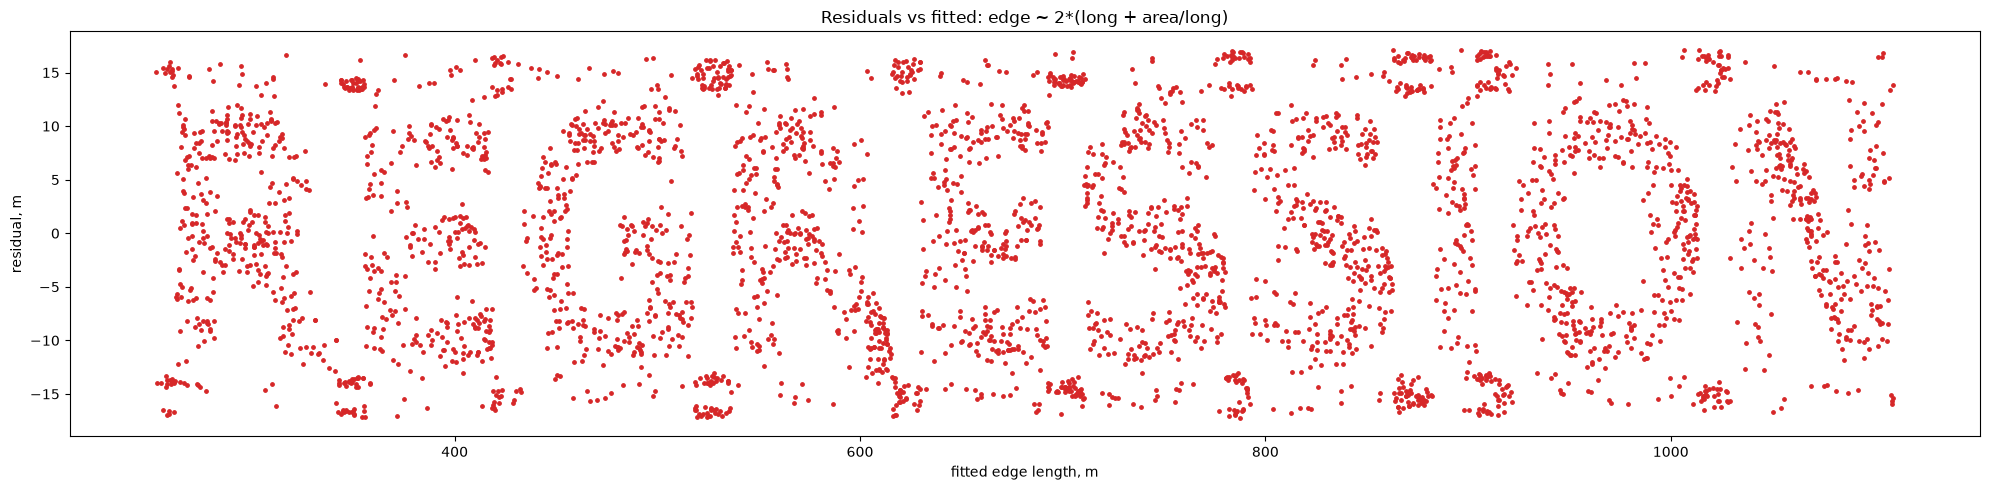

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(20,5))
plt.scatter(df["fitted"], df["residual"], s=6, color="tab:red")
plt.xlabel("fitted edge length, m")
plt.ylabel("residual, m")
plt.title("Residuals vs fitted: edge ~ 2*(long + area/long)")
plt.tight_layout()
plt.savefig("residuals.png", dpi = 110)
plt.show()